# Trabalho Final – Introdução à Ciência de Dados

## 0 - Abertura do notebook
- Nome: Lucas Ferraz Macris - 13828081
- Pergunta: os deputados formam grupos naturais pelo comportamento de voto? Esses grupos correspondem aos partidos?
- Hipóteses:
  - H1: os grupos refletem mais governo × oposição do que o partido
  - H2: região, sexo e idade têm pouca relação com os grupos
  - H3: parte da base do governo Bolsonaro (56ª) virou base do governo Lula (57ª) (centrão)
- Resumo do tratamento: matrizes de voto por legislatura, nulos preenchidos com 0, PCA com 2 componentes, K-means e Ward. Detalhes nas partes 2, 5 e 6.

In [1]:
import os
os.environ['OMP_NUM_THREADS'] = '1'                       
os.environ['LOKY_MAX_CPU_COUNT'] = str(os.cpu_count())    

import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

c:\Users\Lucas\anaconda3\Lib\site-packages\sklearn\utils\_param_validation.py:14: UserWarning: A NumPy version >=1.23.5 and <2.5.0 is required for this version of SciPy (detected version 2.5.4)
  from scipy.sparse import csr_matrix, issparse


## 1 - Carregar os dados tratados
- `matriz_leg56.csv` e `matriz_leg57.csv` (index_col=0): voto de cada deputado em cada votação
- `deputados_info.csv`: partido, região, sexo, idade, novato
- `orientacoes_plenario.csv`: orientação de Governo e Oposição em cada votação
- `votacoes_plenario.csv`: usada só no bloco "Em qual governo aprovou mais coisas"

In [2]:
matriz_56 = pd.read_csv('dados/DadosLimpos/matriz_leg56.csv', index_col=0)   # matrizes: deputado_id é o índice
matriz_57 = pd.read_csv('dados/DadosLimpos/matriz_leg57.csv', index_col=0)
df_orientacoes = pd.read_csv('dados/DadosLimpos/orientacoes_plenario.csv')     # tabelas: sem index_col
df_deputados = pd.read_csv('dados/DadosLimpos/deputados_info.csv')
df_votacoes = pd.read_csv('dados/DadosLimpos/votacoes_plenario.csv')

In [3]:
# Visualização inicial dos dados carregados
print("=== Matriz 56ª Legislatura (Deputados x Votações) ===")
display(matriz_56.head())

print("=== Informações dos Deputados ===")
display(df_deputados.head())

print("=== Orientações de Voto ===")
display(df_orientacoes.head())

=== Matriz 56ª Legislatura (Deputados x Votações) ===


,105464-319,105464-326,1198512-254,1198512-279,1215346-65,1301482-127,15460-156,15460-165,15460-170,15460-176,...,593065-277,593065-280,593065-285,593065-291,593065-305,596844-116,622828-9,945554-180,945554-186,946625-101
deputado_id,,,,,,,,,,,,,,,,,,,,,
66179,-1.0,-1.0,-1.0,1.0,NaN,1.0,-1.0,-1.0,-1.0,-1.0,...,-1.0,1.0,-1.0,-1.0,-1.0,1.0,1.0,-1.0,-1.0,-1.0
66828,-1.0,-1.0,-1.0,1.0,-1.0,-1.0,-1.0,1.0,-1.0,-1.0,...,NaN,1.0,-1.0,-1.0,-1.0,1.0,1.0,-1.0,-1.0,1.0
68720,-1.0,-1.0,1.0,1.0,-1.0,-1.0,1.0,NaN,1.0,-1.0,...,-1.0,1.0,-1.0,-1.0,-1.0,1.0,1.0,-1.0,-1.0,1.0
69871,1.0,1.0,1.0,1.0,NaN,1.0,-1.0,1.0,-1.0,-1.0,...,-1.0,1.0,-1.0,-1.0,-1.0,-1.0,-1.0,1.0,1.0,1.0
72442,1.0,1.0,NaN,NaN,1.0,1.0,-1.0,1.0,-1.0,-1.0,...,NaN,1.0,-1.0,NaN,1.0,1.0,-1.0,1.0,-1.0,-1.0


=== Informações dos Deputados ===


,deputado_idLegislatura,deputado_id,nome,partido,n_partidos,uf,regiao,siglaSexo,idade,novato
0,56,66179,Norma Ayub,DEM,3,ES,Sudeste,F,60,False
1,56,66828,Fausto Pinato,PP,1,SP,Sudeste,M,42,False
2,56,68720,Fábio Henrique,PDT,2,SE,Nordeste,M,47,True
3,56,69871,Bacelar,PODE,2,BA,Nordeste,M,62,False
4,56,72442,Felipe Carreras,PSB,1,PE,Nordeste,M,44,False


=== Orientações de Voto ===


,idVotacao,siglaBancada,orientacao
0,2165194-103,Oposição,Sim
1,2165194-103,PV,Sim
2,2165194-103,PROS,Sim
3,2165194-103,DEM,Sim
4,2165194-103,PSD,Sim


## 2 - Tratar os nulos
- Preencher com 0 (= não se posicionou, mesmo valor da abstenção)
- Efeito colateral: quem falta mais fica mais perto do centro no PCA

In [4]:
matriz_56_fill = matriz_56.fillna(0)
matriz_57_fill = matriz_57.fillna(0)

## 3 - Descrição estatística
- Faltas / presença dos deputados por partido
- Idade dos deputados em cada legislatura

### Faltas por partido

In [5]:
# Tabela de faltas por deputado (faltas = votações com NaN; total = nº de votações)
dep_56 = df_deputados[df_deputados['deputado_idLegislatura'] == 56].set_index('deputado_id')
dep_56['faltas'] = matriz_56.isna().sum(axis=1)
dep_56['total'] = matriz_56.shape[1]
tabela_56 = dep_56[['nome', 'partido', 'faltas', 'total']].reset_index()

dep_57 = df_deputados[df_deputados['deputado_idLegislatura'] == 57].set_index('deputado_id')
dep_57['faltas'] = matriz_57.isna().sum(axis=1)
dep_57['total'] = matriz_57.shape[1]
tabela_57 = dep_57[['nome', 'partido', 'faltas', 'total']].reset_index()

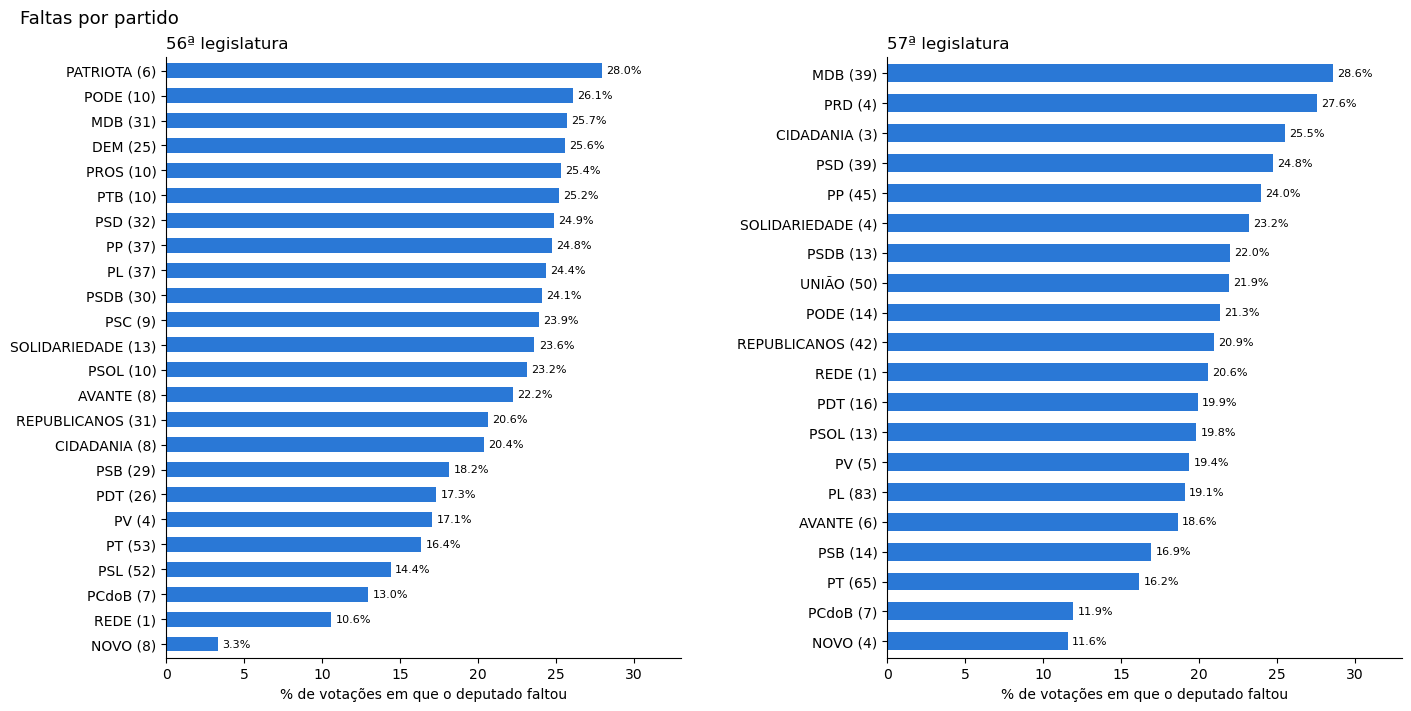

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7), sharex=True, layout='constrained')

for ax, leg, tabela in zip(axes, [56, 57], [tabela_56, tabela_57]):
    por_partido = tabela.groupby('partido')[['faltas', 'total']].sum()    # soma faltas e total de cada partido
    n = tabela['partido'].value_counts()                                  # nº de deputados por partido
    faltas = (por_partido['faltas'] / por_partido['total'] * 100).sort_values()
    faltas.index = [f'{p} ({n[p]})' for p in faltas.index]

    faltas.plot.barh(ax=ax, color='#2a78d6', width=0.6)
    ax.bar_label(ax.containers[0], fmt='%.1f%%', padding=3, fontsize=8)
    ax.set_xlim(0, 33)                       # espaço para o rótulo da maior barra
    ax.set_xlabel('% de votações em que o deputado faltou')
    ax.set_ylabel('')
    ax.set_title(f'{leg}ª legislatura', loc='left')
    ax.spines[['top', 'right']].set_visible(False)

fig.suptitle('Faltas por partido', x=0.01, ha='left', fontsize=13)
fig.get_layout_engine().set(wspace=0.08)
plt.show()

### Presença: base do governo × oposição

Para separar os deputados em **base** e **oposição** sem usar o partido deles, calculamos o **governismo**: a porcentagem de vezes que o deputado votou igual à orientação do Governo (considerando apenas votações em que o Governo orientou "Sim", "Não" ou "Obstrução").
- **Base do governo:** deputados com governismo ≥ 50% (votaram com o governo na maioria das vezes).
- **Oposição:** deputados com governismo < 50%.

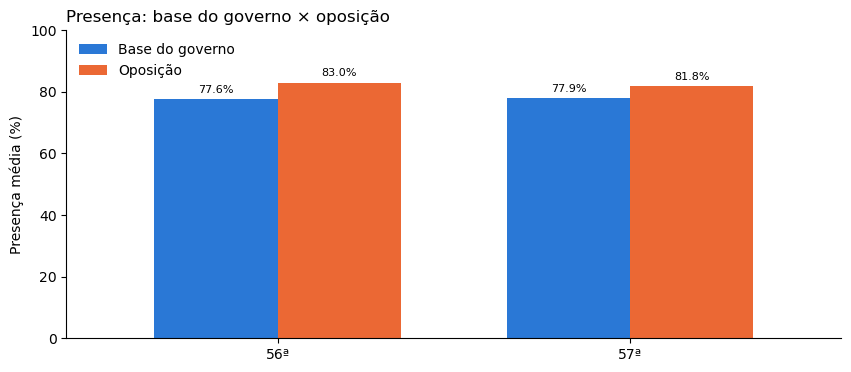

In [7]:
# Orientação do governo em cada votação (Sim = 1, Não/Obstrução = -1; 'Liberado' fica de fora)
gov = df_orientacoes[df_orientacoes['siglaBancada'] == 'Governo'].copy()
gov['orient_num'] = gov['orientacao'].map({'Sim': 1, 'Não': -1, 'Obstrução': -1})
orient_gov = gov.dropna(subset=['orient_num']).drop_duplicates('idVotacao').set_index('idVotacao')['orient_num']

# Governismo de cada deputado = % dos seus votos (Sim/Não) iguais à orientação do governo
# (essa função também é usada na parte 4)
def governismo(matriz):
    cols = matriz.columns.intersection(orient_gov.index)                # votações em que o governo orientou
    votos = matriz[cols]
    votou = votos.isin([1, -1])                                         # votou Sim ou Não
    return (votos.eq(orient_gov[cols], axis=1) & votou).sum(axis=1) / votou.sum(axis=1) * 100

linhas = []
for leg, matriz in zip([56, 57], [matriz_56, matriz_57]):
    presenca = matriz.notna().mean(axis=1) * 100                                   # % de votações em que votou
    grupo = np.where(governismo(matriz) >= 50, 'Base do governo', 'Oposição')      # base = votou com o governo em >= 50%
    linhas.append(pd.DataFrame({'presenca': presenca, 'grupo': grupo, 'legislatura': f'{leg}ª'}))

presenca_grupo = pd.concat(linhas).groupby(['legislatura', 'grupo'])['presenca'].mean().unstack()

ax = presenca_grupo.plot.bar(figsize=(10, 4), color=['#2a78d6', '#eb6834'], width=0.7, rot=0)
for barras in ax.containers:                                            # um container por grupo (base e oposição)
    ax.bar_label(barras, fmt='%.1f%%', padding=3, fontsize=8)
ax.set_ylim(0, 100)
ax.set_xlabel('')
ax.set_ylabel('Presença média (%)')
ax.set_title('Presença: base do governo × oposição', loc='left')
ax.legend(frameon=False)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

## hist de Idade em cada legislatura

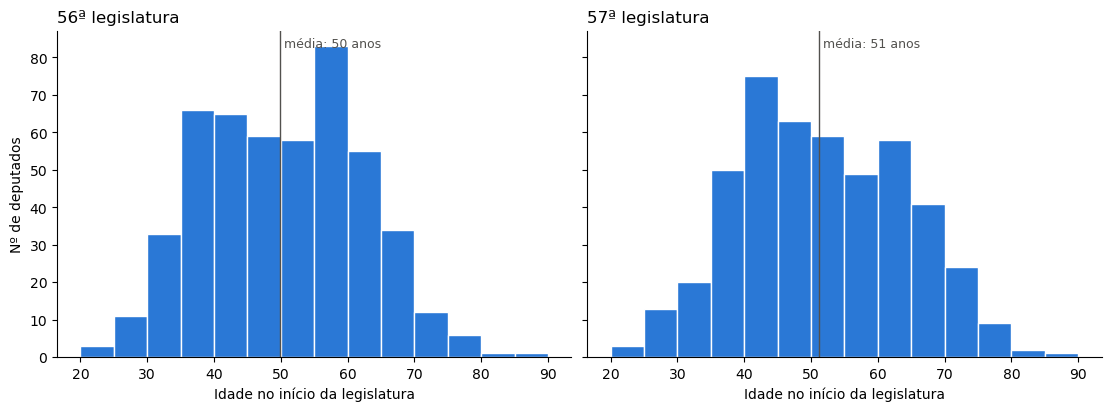

,nº deputados,média,desvio padrão,mínimo,1º quartil,mediana,3º quartil,máximo
legislatura,,,,,,,,
56,487.0,49.8,11.8,23.0,40.0,50.0,58.5,85.0
57,467.0,51.1,12.5,22.0,41.0,50.0,61.0,89.0


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True, layout='constrained')

for ax, leg in zip(axes, [56, 57]):
    idades = df_deputados.loc[df_deputados['deputado_idLegislatura'] == leg, 'idade']
    ax.hist(idades, bins=range(20, 95, 5), color='#2a78d6', edgecolor='white')   # faixas de 5 em 5 anos
    ax.axvline(idades.mean(), color='#52514e', linewidth=1)                      # linha da média
    ax.text(idades.mean(), ax.get_ylim()[1] * 0.95, f' média: {idades.mean():.0f} anos', color='#52514e', fontsize=9)
    ax.set_title(f'{leg}ª legislatura', loc='left')
    ax.set_xlabel('Idade no início da legislatura')
    ax.spines[['top', 'right']].set_visible(False)

axes[0].set_ylabel('Nº de deputados')
plt.show()

# Resumo estatístico da idade em cada legislatura
resumo_idade = df_deputados.groupby('deputado_idLegislatura')['idade'].describe().round(1)
resumo_idade.columns = ['nº deputados', 'média', 'desvio padrão', 'mínimo', '1º quartil', 'mediana', '3º quartil', 'máximo']
resumo_idade.index.name = 'legislatura'
display(resumo_idade)

###  Em qual governo aprovou mais coisas (56ª Bolsonaro × 57ª Lula)

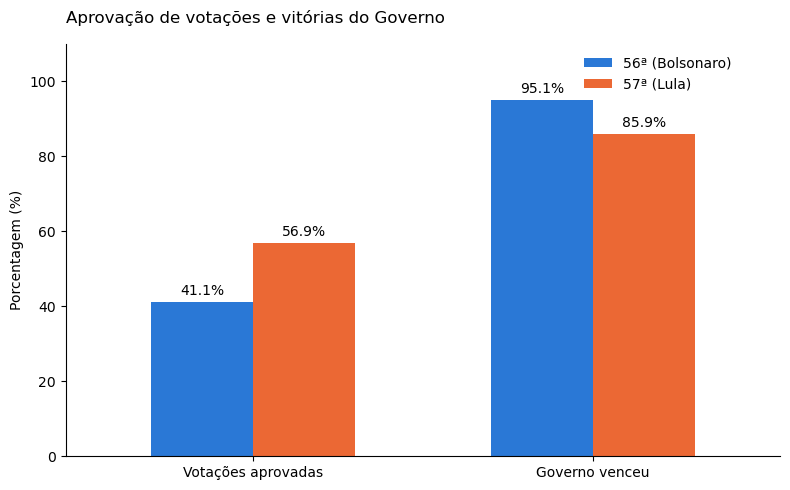

In [9]:
# Legislatura pela data (a 57ª começa em 1º/fev/2023)
df_votacoes['legislatura'] = np.where(pd.to_datetime(df_votacoes['data']) >= '2023-02-01', '57ª (Lula)', '56ª (Bolsonaro)')

# Orientação do governo em cada votação, em texto ('Sim', 'Não', 'Obstrução'...)
# (nome diferente do orient_gov numérico, que é usado pela função governismo)
orient_gov_texto = df_orientacoes[df_orientacoes['siglaBancada'] == 'Governo'].drop_duplicates('idVotacao').set_index('idVotacao')['orientacao']
df_votacoes['orient_gov'] = df_votacoes['id'].map(orient_gov_texto)

# Governo venceu = orientou Sim e foi aprovada, ou orientou Não/Obstrução e foi rejeitada
v = df_votacoes[df_votacoes['orient_gov'].isin(['Sim', 'Não', 'Obstrução']) & df_votacoes['aprovacao'].notna()].copy()
v['gov_venceu'] = np.where(v['orient_gov'] == 'Sim', v['aprovacao'] == 1, v['aprovacao'] == 0)

resultado = pd.DataFrame({
    'Votações aprovadas': df_votacoes.groupby('legislatura')['aprovacao'].mean() * 100,
    'Governo venceu':     v.groupby('legislatura')['gov_venceu'].mean() * 100,
})

# --- Gráfico ---
ax = resultado.T.plot(kind='bar', figsize=(8, 5), color=['#2a78d6', '#eb6834'], width=0.6, rot=0)

# Adiciona os valores numéricos em cima de cada barra
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3, fontsize=10)

# Ajustes visuais do gráfico
ax.set_ylim(0, 110) # Um pouco acima de 100 para o texto não cortar
ax.set_xlabel('')
ax.set_ylabel('Porcentagem (%)')
ax.set_title('Aprovação de votações e vitórias do Governo', loc='left', pad=15)
ax.legend(frameon=False, loc='upper right', bbox_to_anchor=(0.95, 1.0))

# Deixa as barras mais bonitas (esconde as bordas de cima e da direita)
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()

## 4 - Padrões relevantes
- Governismo por partido nas duas legislaturas
- Heatmap de concordância entre partidos
- O problema é de agrupamento (não supervisionado); partido e governismo servem só para validar

### Governismo por partido

**Governismo** de um deputado = % dos seus votos (Sim/Não) iguais à orientação do governo, considerando só as votações em que o governo orientou Sim, Não ou Obstrução. A linha em 50% separa, de forma aproximada, base e oposição.

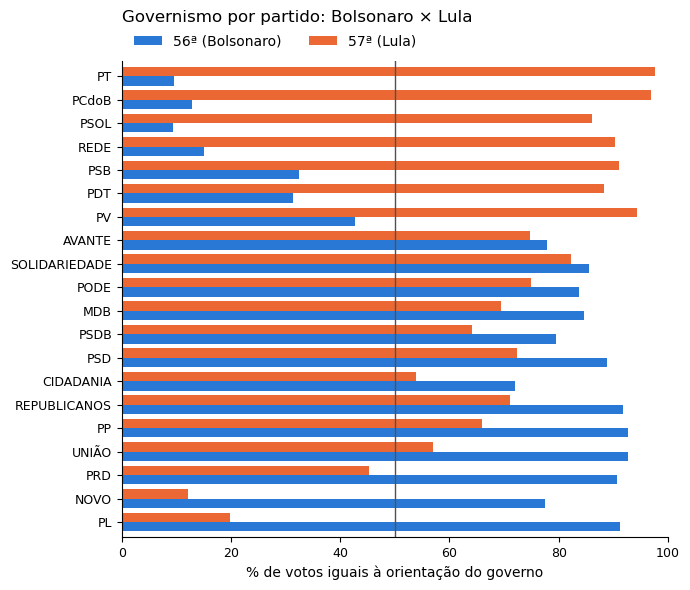

In [10]:
# Partidos que se fundiram entre as legislaturas: o nome da 56ª passa a ser o da 57ª
fusoes = {'PSL': 'UNIÃO', 'DEM': 'UNIÃO', 'PATRIOTA': 'PRD', 'PTB': 'PRD', 'PROS': 'SOLIDARIEDADE', 'PSC': 'PODE'}

gov_partido = {}
for leg, nome, matriz in zip([56, 57], ['56ª (Bolsonaro)', '57ª (Lula)'], [matriz_56, matriz_57]):
    dep = df_deputados[df_deputados['deputado_idLegislatura'] == leg].set_index('deputado_id')
    dep['governismo'] = governismo(matriz)
    dep['partido'] = dep['partido'].replace(fusoes)
    gov_partido[nome] = dep.groupby('partido')['governismo'].mean()

# Uma linha por partido, uma coluna por legislatura (dropna: só partidos que existem nas duas)
comparacao = pd.DataFrame(gov_partido).dropna()

# Ordena pela mudança: no topo quem mais se aproximou do governo Lula, embaixo quem mais se afastou
comparacao = comparacao.loc[(comparacao['57ª (Lula)'] - comparacao['56ª (Bolsonaro)']).sort_values().index]

ax = comparacao.plot.barh(figsize=(7, 6), color=['#2a78d6', '#eb6834'], width=0.8, fontsize=9)

ax.axvline(50, color='#52514e', linewidth=1)                  # linha dos 50%: base x oposição
ax.set_xlim(0, 100)
ax.set_xlabel('% de votos iguais à orientação do governo')
ax.set_ylabel('')
ax.set_title('Governismo por partido: Bolsonaro × Lula', loc='left', pad=28)
ax.legend(frameon=False, ncol=2, loc='lower left', bbox_to_anchor=(0, 1.0))   # legenda acima do gráfico
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

**O que o gráfico mostra:**
- **56ª (Bolsonaro):** a direita e o centrão votam com o governo (72% a 94%); a esquerda fica na oposição (PSOL 9%, PT 10%, PCdoB 13%).
- **57ª (Lula):** os lados se invertem: a esquerda vira base (PT 98%, PCdoB 97%) e o PL vai para a oposição (20%).
- **O centrão (PSD, PP, MDB, Republicanos, União, PSDB) fica acima de 50% nos dois governos**, mas com uma base mais fraca no governo Lula (57% a 72%) do que no Bolsonaro (79% a 93%). Isso é um primeiro indício a favor da **H3**.

### Concordância entre partidos

Em cada votação, a posição de um partido é a da **maioria dos seus deputados** (sinal da soma dos votos). A concordância entre dois partidos é a % das votações em que os dois tiveram a mesma posição. Para o gráfico não ficar poluído, entram só partidos com pelo menos 5 deputados, ordenados do menos ao mais governista.

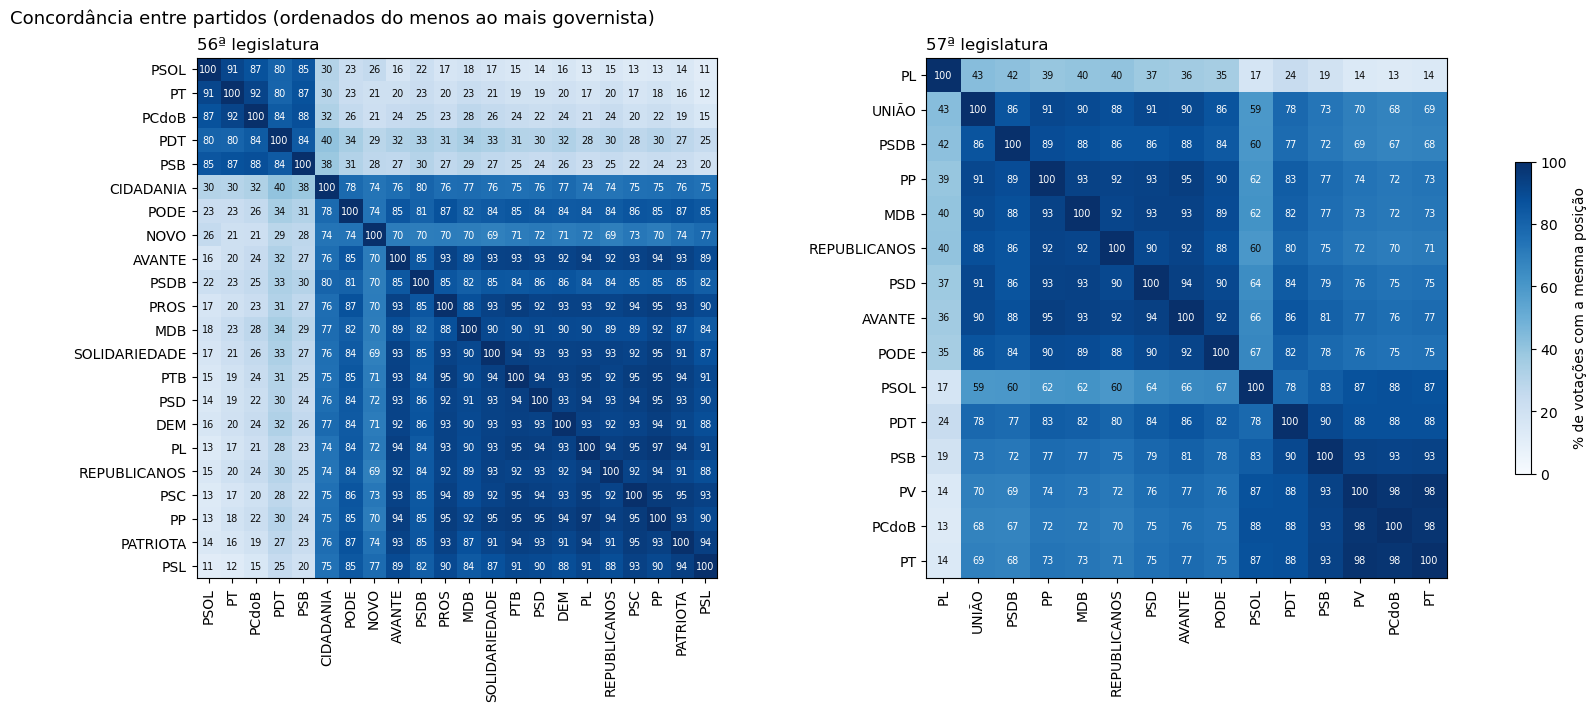

In [11]:
# Concordância entre partidos: em cada votação, a posição do partido é a da maioria dos seus deputados
# (sinal da soma dos votos). Concordância = % das votações em que os dois partidos tiveram a mesma posição.
fig, axes = plt.subplots(1, 2, figsize=(16, 7), layout='constrained')
for ax, leg, matriz in zip(axes, [56, 57], [matriz_56, matriz_57]):
    dep = df_deputados[df_deputados['deputado_idLegislatura'] == leg].set_index('deputado_id')
    grandes = dep['partido'].value_counts()
    grandes = grandes[grandes >= 5].index                            # só partidos com 5+ deputados

    posicao = np.sign(matriz.fillna(0).groupby(dep['partido']).sum()).loc[grandes]   # partido x votação: 1, -1 ou 0
    ordem = governismo(matriz).groupby(dep['partido']).mean().loc[grandes].sort_values().index
    posicao = posicao.loc[ordem]                                     # ordena da oposição para a base

    concordancia = pd.DataFrame({a: {b: (posicao.loc[a] == posicao.loc[b])[(posicao.loc[a] != 0) & (posicao.loc[b] != 0)].mean() * 100
                                     for b in ordem} for a in ordem})

    im = ax.imshow(concordancia, cmap='Blues', vmin=0, vmax=100)
    ax.set_xticks(range(len(ordem)), ordem, rotation=90)
    ax.set_yticks(range(len(ordem)), ordem)
    for i in range(len(ordem)):
        for j in range(len(ordem)):
            v = concordancia.iloc[i, j]
            ax.text(j, i, f'{v:.0f}', ha='center', va='center', fontsize=7, color='white' if v > 60 else '#0b0b0b')
    ax.set_title(f'{leg}ª legislatura', loc='left')
fig.colorbar(im, ax=axes, shrink=0.6, label='% de votações com a mesma posição')
fig.suptitle('Concordância entre partidos (ordenados do menos ao mais governista)', x=0.01, ha='left', fontsize=13)
plt.show()

**O que o gráfico mostra:**
- **56ª:** dois blocos bem definidos: a esquerda (PSOL, PT, PCdoB, PDT, PSB), que concorda entre si em 80% a 100% das votações, e todo o resto (direita + centrão), que concorda entre si em 75% a 100%. Entre os dois blocos a concordância cai para 15% a 40%.
- **57ª:** o **PL fica isolado** (no máximo 44% de concordância com qualquer outro partido). O centrão forma um bloco próprio (84% a 94%) e concorda bem mais com a esquerda (60% a 85%) do que com o PL.
- Os blocos aparecem **antes de qualquer agrupamento**, o que indica que deve haver estrutura de grupos nos dados, e que ela acompanha mais o alinhamento com o governo do que a sigla isolada.

### Tipo de problema

O problema é de **agrupamento (aprendizado não supervisionado)**: queremos descobrir se os deputados formam grupos naturais **apenas a partir dos votos**, sem informar a ninguém o partido ou o lado de cada um.

## 5 - PCA
- Sem padronização (todos os votos já estão na escala de -1 a 1)
- Gráfico de variância explicada por componente (cotovelo) → 2 componentes
- Justificativa dos ~50% de variância: 2 componentes reconstroem ~90% dos votos (contra 71% chutando a maioria)
- Gráfico PC1 × PC2 colorido por partido

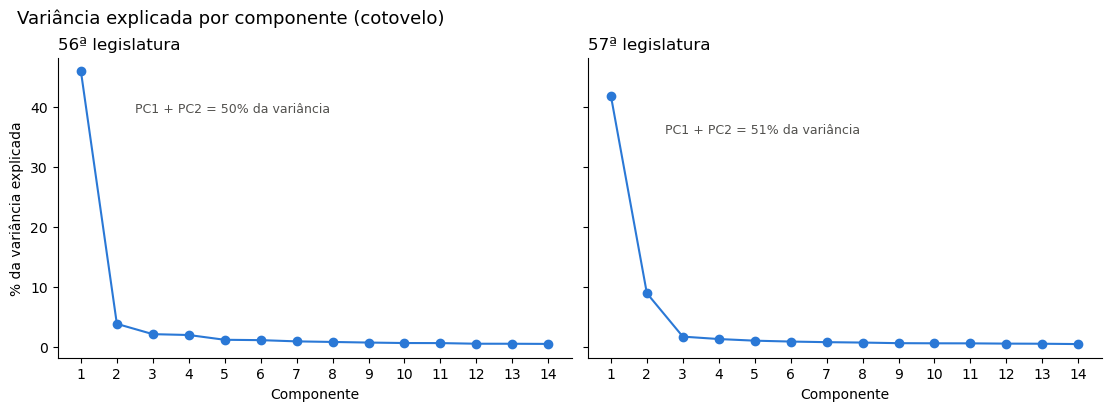

In [12]:
# Variância explicada por componente nas duas legislaturas (gráfico do cotovelo)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True, layout='constrained')

for ax, leg, X in zip(axes, [56, 57], [matriz_56_fill, matriz_57_fill]):
    var = PCA().fit(X).explained_variance_ratio_[:14] * 100        # % da variância dos 14 primeiros componentes
    ax.plot(range(1, 15), var, marker='o', color='#2a78d6')
    ax.text(2.5, var[0] * 0.85, f'PC1 + PC2 = {var[:2].sum():.0f}% da variância', fontsize=9, color='#52514e')
    ax.set_xticks(range(1, 15))
    ax.set_xlabel('Componente')
    ax.set_title(f'{leg}ª legislatura', loc='left')
    ax.spines[['top', 'right']].set_visible(False)

axes[0].set_ylabel('% da variância explicada')
fig.suptitle('Variância explicada por componente (cotovelo)', x=0.01, ha='left', fontsize=13)
plt.show()

**O que o gráfico mostra:** o **PC1 sozinho explica 46% (56ª) e 42% (57ª)** da variância. Depois do 2º componente, cada um acrescenta só 1 a 2%: o **cotovelo está no 2º componente**. Na 57ª o PC2 é bem mais forte (9% contra 4% na 56ª), o que indica uma **segunda divisão importante** na Câmara atual, além de governo × oposição.

Por isso usamos **2 componentes**. Os ~50% de variância parecem pouco, mas o resto está espalhado em centenas de componentes, cada um com menos de 2%: é principalmente ruído (votos isolados e os zeros colocados no lugar das faltas). A tabela abaixo mostra que 2 componentes já guardam quase toda a informação útil.

In [13]:
# Quantos votos reais dá para recuperar usando só k componentes?
# Reconstrói a matriz a partir de k componentes e compara o sinal (+ = Sim, - = Não) com o voto real.
# Referência: "chutar" que todo deputado votou como a maioria da Câmara naquela votação.
linhas = []
for leg, matriz, X in zip([56, 57], [matriz_56, matriz_57], [matriz_56_fill, matriz_57_fill]):
    real = matriz.values
    sim_nao = ~np.isnan(real) & (real != 0)                        # só os votos Sim/Não de verdade
    chute = np.broadcast_to(np.sign(X.mean().values), X.shape)     # voto da maioria em cada votação
    acertos = {'Chute (maioria)': (chute[sim_nao] == real[sim_nao]).mean()}
    for k in [1, 2, 3, 5, 10]:
        pca_k = PCA(n_components=k).fit(X)
        reconstruida = pca_k.inverse_transform(pca_k.transform(X))
        acertos[f'{k} comp.'] = (np.sign(reconstruida)[sim_nao] == real[sim_nao]).mean()
    linhas.append(pd.Series(acertos, name=f'{leg}ª legislatura'))

acerto_pca = (pd.DataFrame(linhas) * 100).round(1)
display(acerto_pca)

,Chute (maioria),1 comp.,2 comp.,3 comp.,5 comp.,10 comp.
56ª legislatura,71.1,88.6,90.3,91.3,92.1,93.3
57ª legislatura,71.5,89.3,90.4,91.1,92.0,93.1


**O que a tabela mostra:** com **só 2 componentes dá para acertar ~90% dos votos Sim/Não reais**, contra 71% de quem "chuta" que todo deputado vota com a maioria. Ir de 2 para 10 componentes ganha só 3 pontos. Ou seja, **2 números por deputado** já resumem quase todo o seu comportamento de voto, o que justifica usar 2 componentes mesmo com ~50% da variância.

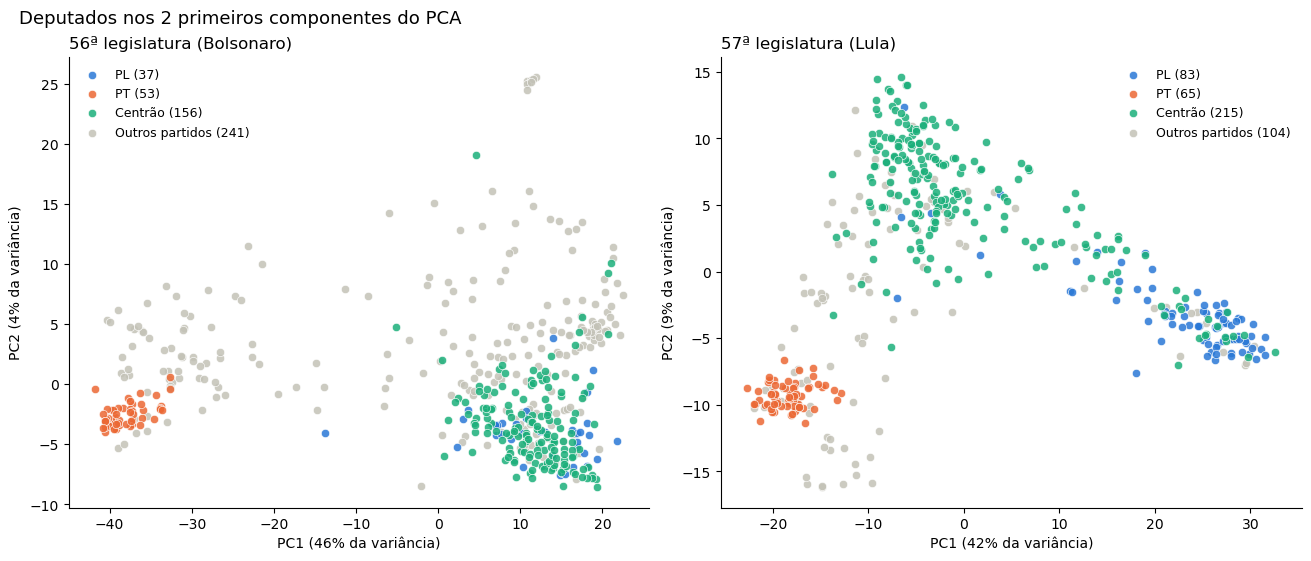

In [14]:
# PCA com 2 componentes: cada deputado vira um ponto (PC1, PC2)
# Cores: PL, PT e o centrão; os demais partidos ficam em cinza
centrao = ['PP', 'PSD', 'MDB', 'REPUBLICANOS', 'DEM', 'UNIÃO']
cores = {'PL': '#2a78d6', 'PT': '#eb6834', 'Centrão': '#1baf7a', 'Outros partidos': '#c3c2b7'}

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), layout='constrained')
for ax, leg, X in zip(axes, [56, 57], [matriz_56_fill, matriz_57_fill]):
    pca2 = PCA(n_components=2).fit(X)
    pcs = pd.DataFrame(pca2.transform(X), index=X.index, columns=['PC1', 'PC2'])

    partido = df_deputados[df_deputados['deputado_idLegislatura'] == leg].set_index('deputado_id')['partido']
    grupo = partido.copy()
    grupo[partido.isin(centrao)] = 'Centrão'
    grupo[~partido.isin(['PT', 'PL'] + centrao)] = 'Outros partidos'
    pcs['grupo'] = grupo

    # O sinal dos componentes é arbitrário: viramos os eixos para o PT ficar sempre embaixo à esquerda
    if pcs.loc[pcs['grupo'] == 'PT', 'PC1'].mean() > 0:
        pcs['PC1'] *= -1
    if pcs.loc[pcs['grupo'] == 'PT', 'PC2'].mean() > 0:
        pcs['PC2'] *= -1

    for g, cor in cores.items():
        d = pcs[pcs['grupo'] == g]
        ax.scatter(d['PC1'], d['PC2'], s=36, color=cor, alpha=0.85, edgecolor='white', linewidth=0.5,
                   label=f'{g} ({len(d)})', zorder=1 if g == 'Outros partidos' else 2)   # cinza fica atrás

    var = pca2.explained_variance_ratio_ * 100
    ax.set_xlabel(f'PC1 ({var[0]:.0f}% da variância)')
    ax.set_ylabel(f'PC2 ({var[1]:.0f}% da variância)')
    ax.set_title(f'{leg}ª legislatura ({"Bolsonaro" if leg == 56 else "Lula"})', loc='left')
    ax.legend(frameon=False, fontsize=9)
    ax.spines[['top', 'right']].set_visible(False)

fig.suptitle('Deputados nos 2 primeiros componentes do PCA', x=0.01, ha='left', fontsize=13)
plt.show()

**O que o gráfico mostra:**
- **56ª (Bolsonaro):** o PC1 separa claramente **dois lados**: o PT (e a esquerda, em cinza) à esquerda, e o **PL e o centrão misturados** à direita. Ou seja, no governo Bolsonaro o centrão votava junto com o PL.
- **57ª (Lula):** aparecem **três grupos**: o PT embaixo à esquerda, o **PL embaixo à direita** e a maior parte do **centrão em cima, no meio**. O PC2 separa o centrão dos dois polos: ele fica entre a base (PT) e a oposição (PL), e não colado a nenhum dos dois. Uma parte menor do centrão se mistura com o PL, à direita.
- Isso reforça a **H1**: os deputados se organizam mais pelo alinhamento com o governo do que pela sigla, e o centrão muda de posição conforme quem governa.

O sinal dos componentes do PCA é arbitrário (o gráfico poderia sair espelhado), por isso os eixos foram virados para o PT ficar sempre embaixo à esquerda e as duas legislaturas serem comparáveis.

## 6 - Agrupamento
- K-means (k escolhido pelo cotovelo e pela silhueta)
- Hierárquico (Ward) + dendrograma

In [15]:
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram, set_link_color_palette

# Dados do agrupamento: os 2 primeiros componentes do PCA de cada legislatura
# (os componentes são virados para o PT ficar sempre embaixo à esquerda, como no gráfico da parte 5)
X_pca = {}
for leg, X in zip([56, 57], [matriz_56_fill, matriz_57_fill]):
    pcs = pd.DataFrame(PCA(n_components=2).fit_transform(X), index=X.index, columns=['PC1', 'PC2'])
    partido = df_deputados[df_deputados['deputado_idLegislatura'] == leg].set_index('deputado_id')['partido']
    pt = partido[partido == 'PT'].index
    if pcs.loc[pt, 'PC1'].mean() > 0:
        pcs['PC1'] *= -1
    if pcs.loc[pt, 'PC2'].mean() > 0:
        pcs['PC2'] *= -1
    X_pca[leg] = pcs

# Os números dos grupos são arbitrários (o "grupo 0" de um método pode ser o "grupo 2" de outro).
# Para comparar e colorir sempre igual, renumeramos os grupos da esquerda para a direita no PC1.
def ordenar_grupos(X, rotulos):
    rotulos = pd.Series(rotulos, index=X.index)
    ordem = X['PC1'].groupby(rotulos).mean().sort_values().index
    return rotulos.map({g: i for i, g in enumerate(ordem)})

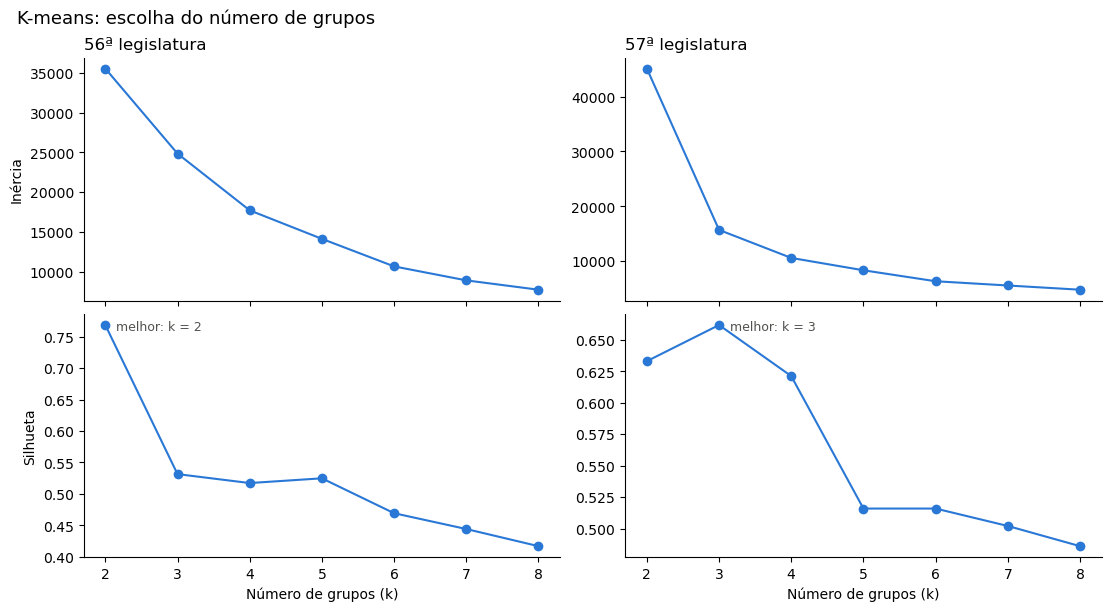

In [16]:
# K-means para k = 2 a 8: inércia (cotovelo) e silhueta
ks = range(2, 9)
fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex=True, layout='constrained')

for j, leg in enumerate([56, 57]):
    X = X_pca[leg]
    inercia, silhueta = [], []
    for k in ks:
        km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
        inercia.append(km.inertia_)                        # soma das distâncias² de cada ponto ao centro do seu grupo
        silhueta.append(silhouette_score(X, km.labels_))   # de -1 a 1: quanto maior, mais separados os grupos

    axes[0, j].plot(ks, inercia, marker='o', color='#2a78d6')
    axes[1, j].plot(ks, silhueta, marker='o', color='#2a78d6')
    melhor = ks[int(np.argmax(silhueta))]
    axes[1, j].annotate(f'melhor: k = {melhor}', (melhor, max(silhueta)), xytext=(8, -4),
                        textcoords='offset points', fontsize=9, color='#52514e')
    axes[0, j].set_title(f'{leg}ª legislatura', loc='left')
    axes[1, j].set_xlabel('Número de grupos (k)')
    for ax in axes[:, j]:
        ax.spines[['top', 'right']].set_visible(False)

axes[0, 0].set_ylabel('Inércia')
axes[1, 0].set_ylabel('Silhueta')
fig.suptitle('K-means: escolha do número de grupos', x=0.01, ha='left', fontsize=13)
plt.show()

**O que o gráfico mostra:**
- **56ª:** a silhueta é bem maior com **k = 2** (0,77) do que com qualquer outro k (no máximo 0,53). A inércia cai de forma suave, sem cotovelo nítido, então a silhueta decide: **2 grupos**.
- **57ª:** a silhueta é máxima em **k = 3** (0,66), e a inércia tem um **cotovelo nítido em k = 3** (cai de ~44.800 para ~15.400 e depois quase não muda). Os dois critérios concordam: **3 grupos**.

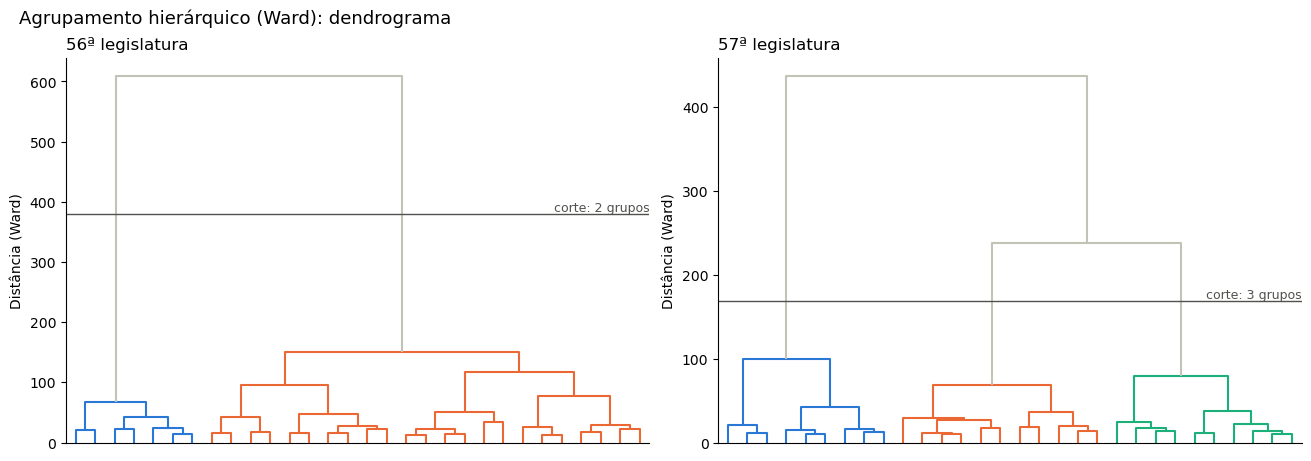

In [17]:
# Agrupamento hierárquico (Ward): junta, passo a passo, os dois grupos cuja união menos aumenta a variância.
# O dendrograma mostra essas junções; cortar onde os "saltos" de altura são grandes dá o número de grupos.
set_link_color_palette(['#2a78d6', '#eb6834', '#1baf7a'])
k_escolhido = {56: 2, 57: 3}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), layout='constrained')
for ax, leg in zip(axes, [56, 57]):
    Z = linkage(X_pca[leg], method='ward')
    k = k_escolhido[leg]
    corte = (Z[-k, 2] + Z[-k + 1, 2]) / 2                  # altura que deixa exatamente k grupos
    dendrogram(Z, ax=ax, truncate_mode='lastp', p=30, color_threshold=corte,
               above_threshold_color='#c3c2b7', no_labels=True)
    ax.axhline(corte, color='#52514e', linewidth=1)
    ax.text(ax.get_xlim()[1], corte, f' corte: {k} grupos', va='bottom', ha='right', fontsize=9, color='#52514e')
    ax.set_title(f'{leg}ª legislatura', loc='left')
    ax.set_ylabel('Distância (Ward)')
    ax.spines[['top', 'right']].set_visible(False)

fig.suptitle('Agrupamento hierárquico (Ward): dendrograma', x=0.01, ha='left', fontsize=13)
plt.show()

**O que o gráfico mostra:** a altura de cada junção no dendrograma indica o quanto os grupos unidos eram diferentes. Na **56ª** há um salto enorme na última junção (dois grandes blocos muito diferentes) → **2 grupos**. Na **57ª** os dois últimos saltos são grandes e os seguintes são pequenos → **3 grupos**. O Ward confirma o número de grupos escolhido com o K-means.

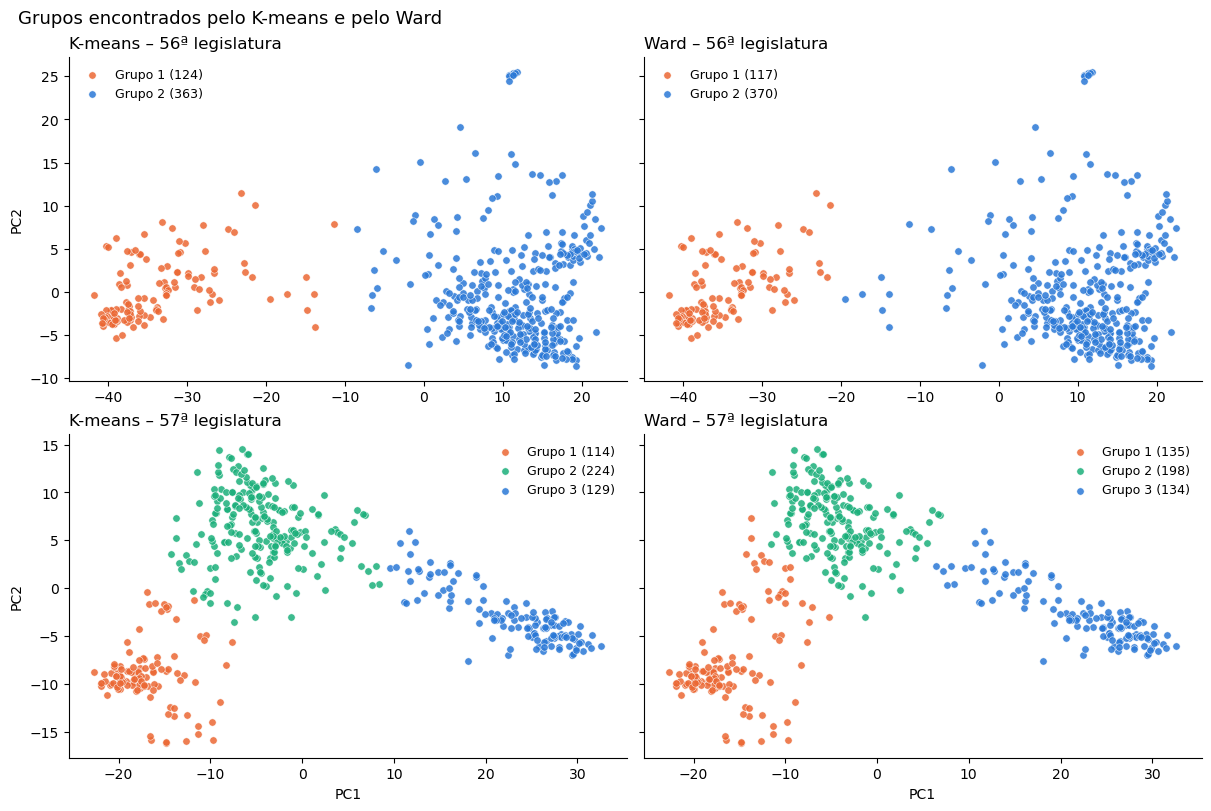

,Grupo 1,Grupo 2
56ª legislatura,,
PT,53,0
PDT,23,3
PSB,23,6
PSOL,10,0
PCdoB,7,0
AVANTE,2,6
PODE,1,9
PSDB,1,29
PL,1,36


,Grupo 1,Grupo 2,Grupo 3
57ª legislatura,,,
PT,65,0,0
PSOL,13,0,0
PSB,12,2,0
PCdoB,7,0,0
PDT,6,10,0
PV,4,1,0
AVANTE,2,3,1
PSDB,1,9,3
PSD,1,35,3


In [18]:
# Agrupamento final com o número de grupos escolhido (2 na 56ª, 3 na 57ª), pelos dois métodos
grupos = {}
for leg in [56, 57]:
    X, k = X_pca[leg], k_escolhido[leg]
    grupos[leg] = pd.DataFrame({
        'K-means': ordenar_grupos(X, KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X)),
        'Ward':    ordenar_grupos(X, AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X)),
    })

# Gráfico: uma linha por legislatura, uma coluna por método
# Cores iguais às dos partidos na parte 5: laranja = grupo da esquerda, azul = grupo do PL/direita, verde = centrão
cores_grupo = {56: {0: '#eb6834', 1: '#2a78d6'},
               57: {0: '#eb6834', 1: '#1baf7a', 2: '#2a78d6'}}
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey='row', layout='constrained')
for i, leg in enumerate([56, 57]):
    for j, metodo in enumerate(['K-means', 'Ward']):
        ax, rot = axes[i, j], grupos[leg][metodo]
        for g in sorted(rot.unique()):
            d = X_pca[leg][rot == g]
            ax.scatter(d['PC1'], d['PC2'], s=28, color=cores_grupo[leg][g], alpha=0.85,
                       edgecolor='white', linewidth=0.4, label=f'Grupo {g + 1} ({len(d)})')
        ax.set_title(f'{metodo} – {leg}ª legislatura', loc='left')
        ax.legend(frameon=False, fontsize=9)
        ax.spines[['top', 'right']].set_visible(False)
        if i == 1: ax.set_xlabel('PC1')
        if j == 0: ax.set_ylabel('PC2')

fig.suptitle('Grupos encontrados pelo K-means e pelo Ward', x=0.01, ha='left', fontsize=13)
plt.show()

# Quantos deputados de cada partido caíram em cada grupo (K-means), só partidos com 5+ deputados
for leg in [56, 57]:
    partido = df_deputados[df_deputados['deputado_idLegislatura'] == leg].set_index('deputado_id')['partido']
    tabela = pd.crosstab(partido.loc[grupos[leg].index], grupos[leg]['K-means'] + 1)
    tabela = tabela[tabela.sum(axis=1) >= 5].sort_values(1, ascending=False)
    tabela.columns = [f'Grupo {g}' for g in tabela.columns]
    tabela.index.name = f'{leg}ª legislatura'
    display(tabela)

**O que o gráfico e as tabelas mostram:**
- Os dois métodos dão praticamente os mesmos grupos: classificam igual **99% (56ª)** e **95% (57ª)** dos deputados.
- **56ª (Bolsonaro): 2 grupos.** Grupo 1 = **esquerda / oposição** (PT, PSOL, PCdoB e a maior parte do PDT e do PSB). Grupo 2 = **base do governo**: PL, PSL e todo o centrão (PP, PSD, MDB, Republicanos, DEM...) juntos.
- **57ª (Lula): 3 grupos.** Grupo 1 = **esquerda** (PT, PSOL, PCdoB, PSB). Grupo 2 = **centrão** (Republicanos, PSD, PP, MDB, União, Podemos). Grupo 3 = **oposição bolsonarista**: quase todo o PL (77 de 83) e uma ala do centrão (17 do União, 11 do PP, 5 do MDB).
- Os grupos **não coincidem com os partidos**: na 56ª vários partidos diferentes caem no mesmo grupo, e na 57ª partidos grandes do centrão ficam divididos entre dois grupos. A comparação com os partidos continua na parte 7.

## 7 - Comparar os modelos
- Silhueta dos grupos (K-means × Ward × partidos)
- 20% das votações separadas para teste: previsão pela maioria do cluster × pela maioria do partido
- Gráfico de acerto por k, com linha do acerto do partido

In [19]:
# Silhueta (de -1 a 1, quanto maior, mais separados os grupos) para cada legislatura e método.
# Referência: a silhueta que teríamos se os "grupos" fossem os próprios partidos.
silhuetas = {}
for leg in [56, 57]:
    X = X_pca[leg]
    partido = df_deputados[df_deputados['deputado_idLegislatura'] == leg].set_index('deputado_id')['partido'].loc[X.index]
    silhuetas[f'{leg}ª legislatura'] = {
        'K-means': silhouette_score(X, grupos[leg]['K-means']),
        'Ward': silhouette_score(X, grupos[leg]['Ward']),
        'Partidos (referência)': silhouette_score(X, partido),
    }

display(pd.DataFrame(silhuetas).round(2))

,56ª legislatura,57ª legislatura
K-means,0.77,0.66
Ward,0.76,0.63
Partidos (referência),-0.15,-0.21


**O que a tabela mostra:**
- K-means e Ward formam grupos bem separados (silhueta 0,77 na 56ª e 0,66 na 57ª) e praticamente empatam entre si.
- Já os **partidos, se usados como grupos, têm silhueta negativa** (−0,15 e −0,22): no espaço dos votos, deputados de partidos diferentes se misturam muito. Ou seja, **os partidos não são os grupos "naturais"** do comportamento de voto, o que é evidência a favor da **H1**.

56ª: K-means k=2: 88.3% | partido: 90.6% | maioria: 70.8%
57ª: K-means k=3: 89.2% | partido: 85.0% | maioria: 71.3%


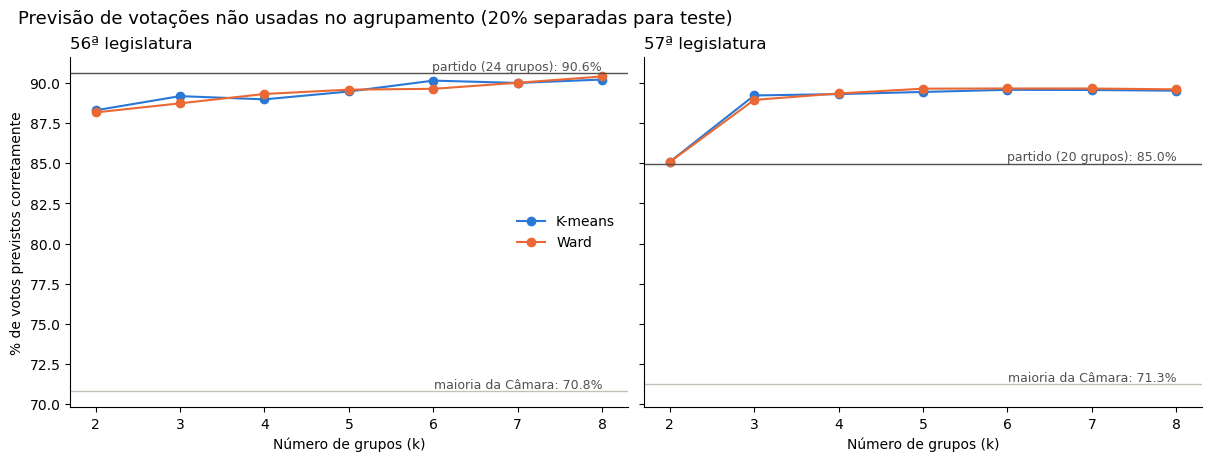

In [20]:
# Validação com votações separadas: os grupos conseguem prever votos que não foram usados para formá-los?
# 1. Separamos 20% das votações (teste) e refazemos PCA + agrupamento só com os outros 80% (treino).
# 2. Em cada votação de teste, o voto previsto de um deputado é o da maioria do seu grupo
#    (sem contar o próprio voto dele). Comparamos com o voto real (só Sim/Não).
# 3. Fazemos o mesmo usando o partido como "grupo", e a maioria da Câmara inteira como referência mínima.
def acerto_por_grupo(M_teste, grupo):
    votos = M_teste.fillna(0)
    soma_grupo = votos.groupby(grupo).transform('sum')      # soma dos votos do grupo em cada votação
    previsto = np.sign(soma_grupo - votos)                  # tira o próprio voto; o sinal diz Sim (+) ou Não (-)
    real = M_teste.notna() & (M_teste != 0)                 # só conta votos Sim/Não de verdade
    return (previsto[real] == M_teste[real]).sum().sum() / real.sum().sum() * 100

rng = np.random.default_rng(42)
ks = range(2, 9)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True, layout='constrained')

for ax, leg, matriz in zip(axes, [56, 57], [matriz_56, matriz_57]):
    teste = rng.choice(matriz.columns.to_numpy(), size=int(0.2 * matriz.shape[1]), replace=False)
    M_teste, M_treino = matriz[teste], matriz.drop(columns=teste)
    X_treino = PCA(n_components=2).fit_transform(M_treino.fillna(0))

    acerto_km = [acerto_por_grupo(M_teste, pd.Series(KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X_treino), index=matriz.index)) for k in ks]
    acerto_ward = [acerto_por_grupo(M_teste, pd.Series(AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X_treino), index=matriz.index)) for k in ks]
    partido = df_deputados[df_deputados['deputado_idLegislatura'] == leg].set_index('deputado_id')['partido'].loc[matriz.index]
    acerto_partido = acerto_por_grupo(M_teste, partido)
    acerto_maioria = acerto_por_grupo(M_teste, pd.Series(0, index=matriz.index))   # todos no mesmo "grupo"

    ax.plot(ks, acerto_km, marker='o', color='#2a78d6', label='K-means')
    ax.plot(ks, acerto_ward, marker='o', color='#eb6834', label='Ward')
    ax.axhline(acerto_partido, color='#52514e', linewidth=1)
    ax.text(8, acerto_partido, f'partido ({partido.nunique()} grupos): {acerto_partido:.1f}%', ha='right', va='bottom', fontsize=9, color='#52514e')
    ax.axhline(acerto_maioria, color='#c3c2b7', linewidth=1)
    ax.text(8, acerto_maioria, f'maioria da Câmara: {acerto_maioria:.1f}%', ha='right', va='bottom', fontsize=9, color='#52514e')
    ax.set_title(f'{leg}ª legislatura', loc='left')
    ax.set_xlabel('Número de grupos (k)')
    ax.spines[['top', 'right']].set_visible(False)
    print(f'{leg}ª: K-means k={k_escolhido[leg]}: {acerto_km[k_escolhido[leg] - 2]:.1f}% | partido: {acerto_partido:.1f}% | maioria: {acerto_maioria:.1f}%')

axes[0].set_ylabel('% de votos previstos corretamente')
axes[0].legend(frameon=False, loc='center right')
fig.suptitle('Previsão de votações não usadas no agrupamento (20% separadas para teste)', x=0.01, ha='left', fontsize=13)
plt.show()

**O que o gráfico mostra:**
- Os grupos foram formados **sem as votações de teste**, então o acerto mede se eles capturam um comportamento real, e não se só "decoraram" os dados.
- **56ª:** com 2 grupos o acerto é de **88%**, quase o mesmo do partido (**91%**), que usa 24 grupos. Com k = 8 chega a 90%, praticamente empatando com o partido.
- **57ª:** com 3 grupos o acerto é de **89%**, **maior que o do partido (85%)**, mesmo o partido tendo 20 grupos. Ou seja, saber em qual dos 3 blocos um deputado está diz mais sobre como ele vai votar do que saber o partido dele.
- Todos ficam muito acima da referência mínima (votar sempre com a maioria da Câmara: ~71%).
- Isso reforça a **H1**, principalmente no governo Lula, em que os partidos do centrão se dividem e a sigla deixa de ser um bom guia do voto.

## 8 - Tentar melhorar (variações)
- Número de componentes do PCA: 2, 3, 5, 10, sem PCA
- Preenchimento dos nulos: 0 × KNNImputer
- Corte de presença: ≥ 70% (a versão principal já vem com o corte de 50% do pré-processamento; esta variação aperta para 70%)
- Obstrução como Não × como 0
- Tabela comparando as métricas de cada variação

In [21]:
from sklearn.impute import KNNImputer

# Votações de conflito: Governo e Oposição orientaram diferente (Obstrução conta como Não; "Liberado" fica de fora)
orient = (df_orientacoes[df_orientacoes['siglaBancada'].isin(['Governo', 'Oposição'])]
          .replace({'orientacao': {'Obstrução': 'Não'}})
          .pivot_table(index='idVotacao', columns='siglaBancada', values='orientacao', aggfunc='first')
          .dropna())
conflito = orient[(orient['Governo'] != orient['Oposição']) & (orient != 'Liberado').all(axis=1)].index

# Votos "Obstrução": na matriz eles valem -1 (como Não). Lemos dos dados brutos para testar tratá-los como 0
obstrucao = pd.concat([pd.read_csv(f'dados/DadosBrutos/votacoesVotos-{ano}.csv', sep=';', encoding='utf-8-sig',
                                   usecols=['idVotacao', 'deputado_id', 'voto']) for ano in range(2019, 2027)])
obstrucao = (obstrucao[obstrucao['voto'] == 'Obstrução'].assign(x=1)
             .pivot_table(index='deputado_id', columns='idVotacao', values='x', aggfunc='first'))

def agrupar(M, k, n_comp=2, preencher='zero'):
    # Preenche os nulos (0 ou KNN), aplica PCA (ou não) e roda o K-means; devolve o grupo de cada deputado
    if preencher == 'knn':
        X = pd.DataFrame(KNNImputer(n_neighbors=10).fit_transform(M), index=M.index)
    else:
        X = M.fillna(0)
    if n_comp is not None:
        X = PCA(n_components=n_comp).fit_transform(X)
    return pd.Series(KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X), index=M.index)

def concordancia(rot, rot_principal):
    # % de deputados no "mesmo" grupo do agrupamento principal
    # (cada grupo da variação é ligado ao grupo principal com que mais compartilha deputados)
    comum = rot.index.intersection(rot_principal.index)
    mapa = pd.crosstab(rot[comum], rot_principal[comum]).idxmax(axis=1)
    return (rot[comum].map(mapa) == rot_principal[comum]).mean() * 100

print(f'Votações de conflito: {len(conflito)}')

Votações de conflito: 1106


In [22]:
# Cada variação refaz o agrupamento (K-means, mesmo k) com uma mudança no tratamento,
# usando as MESMAS votações de teste da parte 7 (mesma semente), para a comparação ser justa.
rng = np.random.default_rng(42)
resultados = []
for leg, matriz in zip([56, 57], [matriz_56, matriz_57]):
    k = k_escolhido[leg]
    teste = rng.choice(matriz.columns.to_numpy(), size=int(0.2 * matriz.shape[1]), replace=False)
    M_teste, M_treino = matriz[teste], matriz.drop(columns=teste)

    obs = obstrucao.reindex(index=M_treino.index, columns=M_treino.columns).notna()   # onde houve obstrução
    presenca = matriz.notna().mean(axis=1)

    variacoes = {
        'Principal (2 comp., nulos = 0)': agrupar(M_treino, k),
        '3 componentes':                  agrupar(M_treino, k, n_comp=3),
        '5 componentes':                  agrupar(M_treino, k, n_comp=5),
        '10 componentes':                 agrupar(M_treino, k, n_comp=10),
        'Sem PCA':                        agrupar(M_treino, k, n_comp=None),
        'Nulos preenchidos com KNN':      agrupar(M_treino, k, preencher='knn'),
        'Presença ≥ 70%':                 agrupar(M_treino[presenca >= 0.7], k),
        'Só votações de conflito':        agrupar(M_treino[M_treino.columns.intersection(conflito)], k),
        'Obstrução = 0 (em vez de Não)':  agrupar(M_treino.mask(obs, 0), k),
    }
    for nome, rot in variacoes.items():
        resultados.append({'Variação': nome, 'Legislatura': f'{leg}ª',
                           'Deputados': len(rot),
                           'Acerto (%)': acerto_por_grupo(M_teste.loc[rot.index], rot),
                           'Concordância (%)': concordancia(rot, variacoes['Principal (2 comp., nulos = 0)'])})

tabela_var = pd.DataFrame(resultados).pivot(index='Variação', columns='Legislatura').reindex(list(variacoes))
tabela_var = tabela_var.swaplevel(axis=1).sort_index(axis=1, level=0)[['56ª', '57ª']]
display(tabela_var.round(1))

Legislatura                           56ª                             \
                               Acerto (%) Concordância (%) Deputados   
Variação                                                               
Principal (2 comp., nulos = 0)       88.3            100.0       487   
3 componentes                        88.3            100.0       487   
5 componentes                        88.3            100.0       487   
10 componentes                       88.3            100.0       487   
Sem PCA                              88.3            100.0       487   
Nulos preenchidos com KNN            88.3            100.0       487   
Presença ≥ 70%                       88.0            100.0       379   
Só votações de conflito              88.3            100.0       487   
Obstrução = 0 (em vez de Não)        88.3            100.0       487   

Legislatura                           57ª                             
                               Acerto (%) Concordância (%) Deputados  
Variação                                                              
Principal (2 comp., nulos = 0)       89.2            100.0       467  
3 componentes                        89.1             99.8       467  
5 componentes                        89.2            100.0       467  
10 componentes                       89.2            100.0       467  
Sem PCA                              89.2            100.0       467  
Nulos preenchidos com KNN            89.2             98.7       467  
Presença ≥ 70%                       89.3             99.7       370  
Só votações de conflito              89.1             98.7       467  
Obstrução = 0 (em vez de Não)        89.2             99.8       467

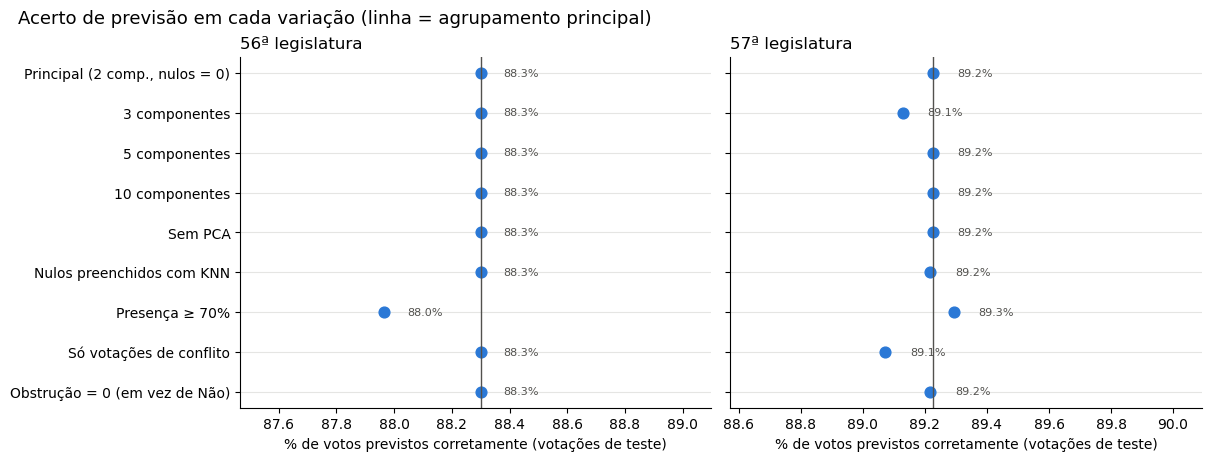

In [23]:
# Acerto de cada variação (pontos), com a linha do agrupamento principal como referência
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True, layout='constrained')
nomes_var = list(variacoes)[::-1]                          # principal fica em cima
for ax, leg in zip(axes, ['56ª', '57ª']):
    acertos = tabela_var[(leg, 'Acerto (%)')].loc[nomes_var]
    ax.scatter(acertos, nomes_var, s=60, color='#2a78d6', zorder=2)
    ax.axvline(acertos.iloc[-1], color='#52514e', linewidth=1)
    for y, v in enumerate(acertos):
        ax.text(v + 0.08, y, f'{v:.1f}%', va='center', fontsize=8, color='#52514e')
    ax.set_xlim(acertos.min() - 0.5, acertos.max() + 0.8)
    ax.set_title(f'{leg} legislatura', loc='left')
    ax.set_xlabel('% de votos previstos corretamente (votações de teste)')
    ax.grid(axis='y', color='#e5e5e3', linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
fig.suptitle('Acerto de previsão em cada variação (linha = agrupamento principal)', x=0.01, ha='left', fontsize=13)
plt.show()

**O que a tabela e o gráfico mostram:**
- **Nenhuma variação melhora o resultado de forma relevante**: o acerto muda no máximo 0,4 ponto, e a concordância com o agrupamento principal fica entre 98% e 100%. Praticamente os mesmos deputados caem nos mesmos grupos, qualquer que seja a escolha.
- Usar 3, 5 ou 10 componentes, ou nem usar PCA, dá os mesmos grupos: a estrutura dos votos está toda nos primeiros componentes.
- Preencher os nulos com KNN ou tratar a Obstrução como 0 também não muda nada. Ou seja, essas escolhas do tratamento **não influenciaram as conclusões**.
- A única mudança no acerto é com presença ≥ 70%, e ela acontece porque o teste passa a usar menos deputados (379 e 367), não porque os grupos melhoraram.
- **Conclusão:** os grupos são **robustos**. Mantemos a versão principal, que é a mais simples (2 componentes, nulos = 0).

## 9 - Resultados finais
- PC1 × PC2 colorido por cluster, ao lado do mesmo gráfico colorido por partido
- Heatmap da tabela cruzada cluster × partido
- Perfil de cada cluster: governismo, presença, idade, sexo, novatos e região
- Governismo 56ª × 57ª para os deputados que estiveram nas duas legislaturas (dispersão + tabela)

In [24]:
# Tabela final de cada legislatura: grupo (K-means) + informações de cada deputado
# Os nomes dos grupos vêm da composição vista na parte 6
nomes_grupos = {56: {0: 'Oposição (esquerda)', 1: 'Base (direita + centrão)'},
                57: {0: 'Base (esquerda)', 1: 'Centrão', 2: 'Oposição (PL + ala do centrão)'}}
cores_nomes = {'Oposição (esquerda)': '#eb6834', 'Base (esquerda)': '#eb6834', 'Centrão': '#1baf7a',
               'Base (direita + centrão)': '#2a78d6', 'Oposição (PL + ala do centrão)': '#2a78d6'}

final = {}
for leg, matriz in zip([56, 57], [matriz_56, matriz_57]):
    dep = df_deputados[df_deputados['deputado_idLegislatura'] == leg].set_index('deputado_id').loc[matriz.index].copy()
    dep['grupo'] = grupos[leg]['K-means'].map(nomes_grupos[leg])
    dep['governismo'] = governismo(matriz)
    dep['presenca'] = matriz.notna().mean(axis=1) * 100
    dep[['PC1', 'PC2']] = X_pca[leg]
    final[leg] = dep

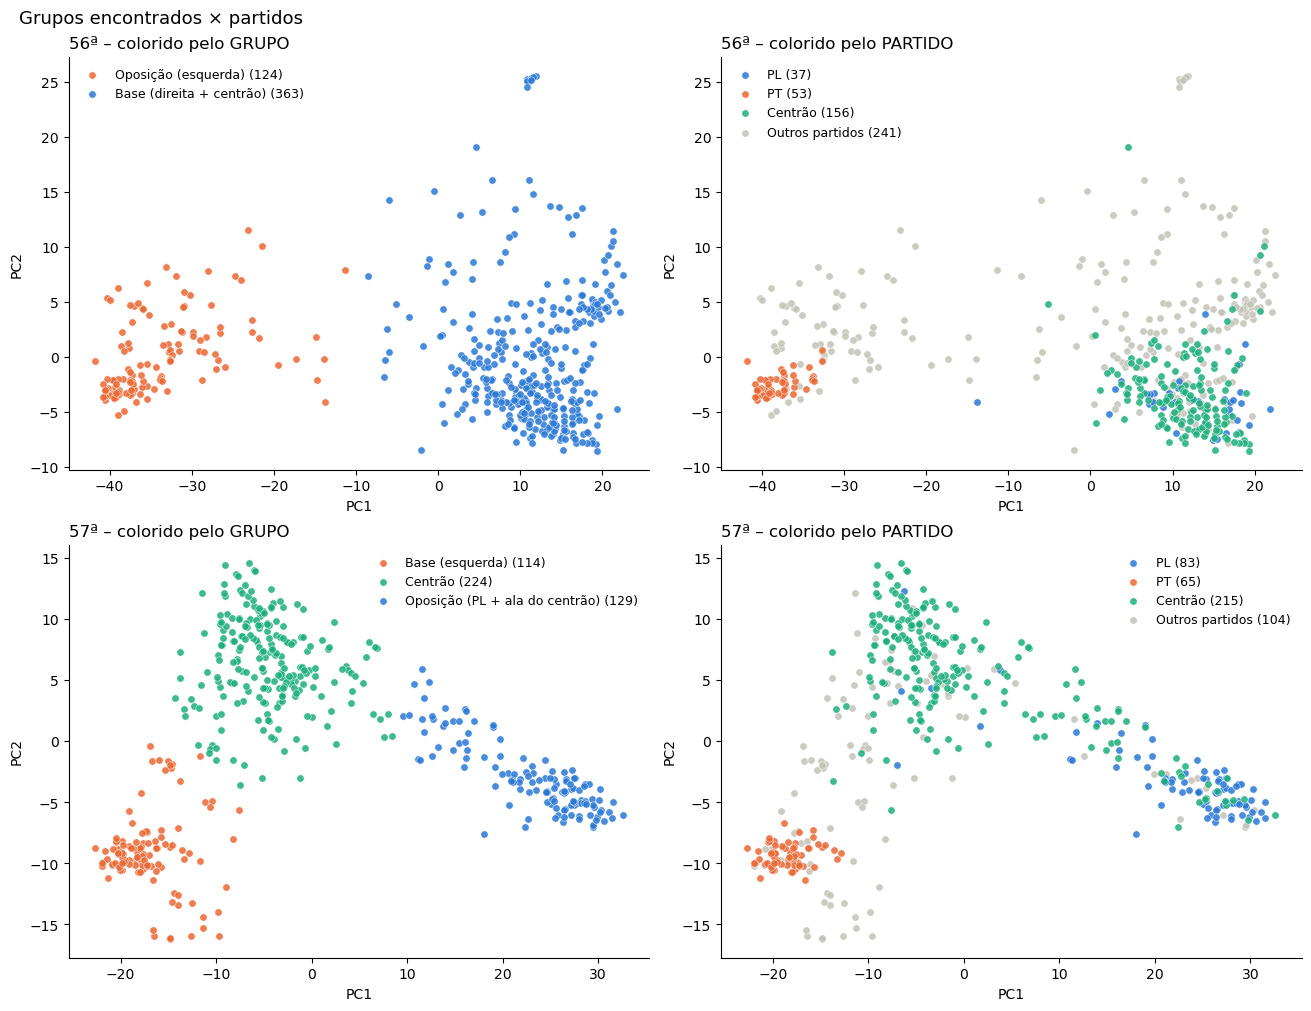

In [25]:
# Lado a lado: os deputados coloridos pelo grupo encontrado (esquerda) e pelo partido (direita)
fig, axes = plt.subplots(2, 2, figsize=(13, 10), layout='constrained')
for i, leg in enumerate([56, 57]):
    d = final[leg]

    for nome in nomes_grupos[leg].values():
        s = d[d['grupo'] == nome]
        axes[i, 0].scatter(s['PC1'], s['PC2'], s=28, color=cores_nomes[nome], alpha=0.85,
                           edgecolor='white', linewidth=0.4, label=f'{nome} ({len(s)})')
    axes[i, 0].set_title(f'{leg}ª – colorido pelo GRUPO', loc='left')

    cor_partido = d['partido'].where(d['partido'].isin(['PT', 'PL']), np.where(d['partido'].isin(centrao), 'Centrão', 'Outros partidos'))
    for g, cor in cores.items():                                   # mesmas cores da parte 5
        s = d[cor_partido == g]
        axes[i, 1].scatter(s['PC1'], s['PC2'], s=28, color=cor, alpha=0.85, edgecolor='white', linewidth=0.4,
                           label=f'{g} ({len(s)})', zorder=1 if g == 'Outros partidos' else 2)
    axes[i, 1].set_title(f'{leg}ª – colorido pelo PARTIDO', loc='left')

    for ax in axes[i]:
        ax.legend(frameon=False, fontsize=9)
        ax.set_xlabel('PC1')
        ax.set_ylabel('PC2')
        ax.spines[['top', 'right']].set_visible(False)

fig.suptitle('Grupos encontrados × partidos', x=0.01, ha='left', fontsize=13)
plt.show()

**O que o gráfico mostra:** os grupos coincidem com **blocos políticos**, não com as siglas. Na 56ª, o grupo azul junta o PL e o centrão (verde no gráfico de partidos). Na 57ª, o centrão vira um grupo próprio (verde), e a parte do centrão mais próxima do PL fica no grupo da oposição (azul).

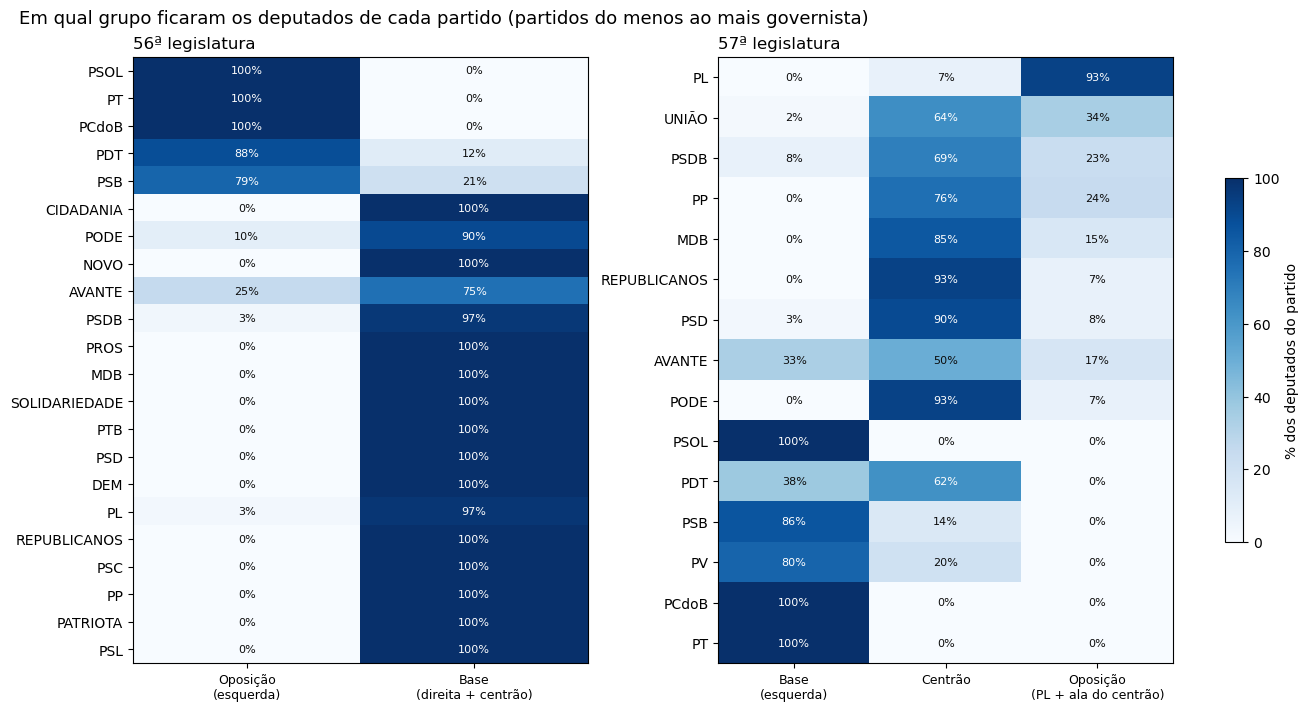

In [26]:
# % dos deputados de cada partido que caiu em cada grupo (partidos com 5+ deputados)
fig, axes = plt.subplots(1, 2, figsize=(13, 7), layout='constrained')
for ax, leg in zip(axes, [56, 57]):
    d = final[leg]
    grandes = d['partido'].value_counts()
    grandes = grandes[grandes >= 5].index
    tab = pd.crosstab(d['partido'], d['grupo'], normalize='index').loc[grandes, list(nomes_grupos[leg].values())] * 100
    tab = tab.loc[d.loc[d['partido'].isin(grandes)].groupby('partido')['governismo'].mean().sort_values().index]   # do menos ao mais governista

    im = ax.imshow(tab, cmap='Blues', vmin=0, vmax=100, aspect='auto')
    ax.set_xticks(range(tab.shape[1]), [c.replace(' (', '\n(') for c in tab.columns], fontsize=9)
    ax.set_yticks(range(tab.shape[0]), tab.index)
    for r in range(tab.shape[0]):
        for c in range(tab.shape[1]):
            v = tab.iloc[r, c]
            ax.text(c, r, f'{v:.0f}%', ha='center', va='center', fontsize=8, color='white' if v > 60 else '#0b0b0b')
    ax.set_title(f'{leg}ª legislatura', loc='left')
fig.colorbar(im, ax=axes, shrink=0.6, label='% dos deputados do partido')
fig.suptitle('Em qual grupo ficaram os deputados de cada partido (partidos do menos ao mais governista)', x=0.01, ha='left', fontsize=13)
plt.show()

**O que o gráfico mostra:**
- **56ª:** a divisão é quase perfeita por bloco: PSOL, PT e PCdoB estão 100% no grupo da oposição, e o centrão e a direita (PL, PSL, PP, PSD, MDB...) estão praticamente 100% no grupo da base. Só PDT (12%), PSB (21%) e Avante (25%) se dividem.
- **57ª:** a esquerda continua unida (PT, PSOL e PCdoB 100% na base), e o PL fica quase todo na oposição (93%). Já o **centrão se divide**: União (64% centrão / 34% oposição), PP (76% / 24%), PSDB (69% / 23%) e MDB (87% / 13%). No governo Lula, a sigla não diz de que lado o deputado está.

In [27]:
# Perfil de cada grupo: governismo, presença, idade, sexo, novatos e região
perfis = []
for leg in [56, 57]:
    d = final[leg]
    p = d.groupby('grupo').agg(**{
        'Deputados': ('nome', 'size'),
        'Governismo (%)': ('governismo', 'mean'),
        'Presença (%)': ('presenca', 'mean'),
        'Idade média': ('idade', 'mean'),
        'Mulheres (%)': ('siglaSexo', lambda s: (s == 'F').mean() * 100),
        'Novatos (%)': ('novato', lambda s: s.mean() * 100),
    })
    p = p.join(pd.crosstab(d['grupo'], d['regiao'], normalize='index') * 100)   # % de cada região no grupo
    p = p.loc[list(nomes_grupos[leg].values())]
    p.index = [f'{leg}ª – {g}' for g in p.index]
    perfis.append(p)

perfil = pd.concat(perfis).round(1)
display(perfil)

,Deputados,Governismo (%),Presença (%),Idade média,Mulheres (%),Novatos (%),Centro-Oeste,Nordeste,Norte,Sudeste,Sul
56ª – Oposição (esquerda),124,16.1,83.1,53.4,20.2,38.7,6.5,36.3,11.3,33.1,12.9
56ª – Base (direita + centrão),363,88.4,77.6,48.6,13.8,53.2,8.5,26.2,13.5,35.8,16.0
57ª – Base (esquerda),114,94.9,83.3,54.2,27.2,34.2,6.1,36.0,3.5,41.2,13.2
57ª – Centrão,224,76.5,75.1,50.2,12.5,45.5,8.5,33.9,15.2,32.6,9.8
57ª – Oposição (PL + ala do centrão),129,19.2,82.0,50.1,17.8,42.6,10.1,17.8,15.5,31.0,25.6


**O que a tabela mostra (H2):**
- O **governismo** é o que mais diferencia os grupos (16% × 88% na 56ª; 95%, 76% e 19% na 57ª): os grupos são, antes de tudo, políticos.
- **Região:** há diferenças. A oposição bolsonarista da 57ª tem bem mais deputados do **Sul (24%)** e menos do **Nordeste (18%)** que os outros grupos (11–13% e 34–36%). Na 56ª, a esquerda tem mais nordestinos que a base do Bolsonaro (36% × 26%).
- **Sexo:** a esquerda tem mais mulheres (20% e 27%) do que os outros grupos (12% a 18%).
- **Idade e novatos:** a esquerda é um pouco mais velha (53–54 anos × 49–50) e tem menos novatos (35–39% × 43–53%).
- **Presença:** a esquerda e a oposição faltam menos (presença de 82–83%) que o centrão e a base do Bolsonaro (75–78%).
- Ou seja, região e sexo têm **alguma** relação com os grupos, provavelmente porque refletem onde e como cada partido é forte, mas bem menor que o alinhamento com o governo.

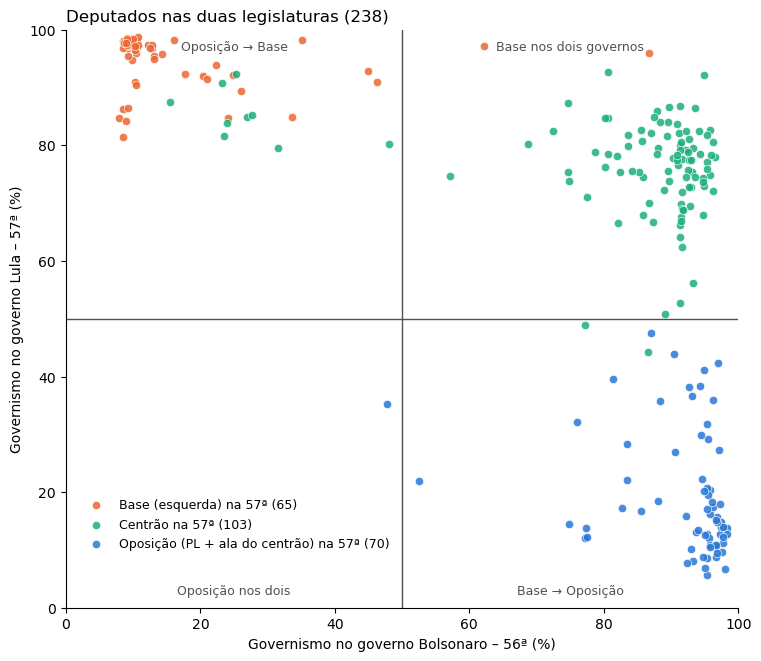

col_0,Base do Lula,Oposição ao Lula,Total
row_0,,,
Base do Bolsonaro,94,71,165
Oposição ao Bolsonaro,72,1,73
Total,166,72,238


In [28]:
# Deputados que estiveram nas duas legislaturas: governismo no governo Bolsonaro × no governo Lula
duas = pd.DataFrame({'gov56': final[56]['governismo'], 'gov57': final[57]['governismo']}).dropna()
duas['grupo57'] = final[57]['grupo']

fig, ax = plt.subplots(figsize=(7.5, 6.5), layout='constrained')
for nome in nomes_grupos[57].values():
    s = duas[duas['grupo57'] == nome]
    ax.scatter(s['gov56'], s['gov57'], s=36, color=cores_nomes[nome], alpha=0.85, edgecolor='white',
               linewidth=0.5, label=f'{nome} na 57ª ({len(s)})')
ax.axvline(50, color='#52514e', linewidth=1)
ax.axhline(50, color='#52514e', linewidth=1)
for x, y, texto in [(75, 97, 'Base nos dois governos'), (25, 97, 'Oposição → Base'),
                    (75, 3, 'Base → Oposição'), (25, 3, 'Oposição nos dois')]:
    ax.text(x, y, texto, ha='center', va='center', fontsize=9, color='#52514e')
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.set_xlabel('Governismo no governo Bolsonaro – 56ª (%)')
ax.set_ylabel('Governismo no governo Lula – 57ª (%)')
ax.set_title(f'Deputados nas duas legislaturas ({len(duas)})', loc='left')
ax.legend(frameon=False, fontsize=9, loc='lower left', bbox_to_anchor=(0.01, 0.08))   # no canto vazio
ax.spines[['top', 'right']].set_visible(False)
plt.show()

# Quantos estavam na base / oposição em cada governo
lado56 = np.where(duas['gov56'] >= 50, 'Base do Bolsonaro', 'Oposição ao Bolsonaro')
lado57 = np.where(duas['gov57'] >= 50, 'Base do Lula', 'Oposição ao Lula')
display(pd.crosstab(lado56, lado57, margins=True, margins_name='Total'))

**O que o gráfico e a tabela mostram (H3):**
- **237 deputados** estiveram nas duas legislaturas.
- Dos **164** que eram base do Bolsonaro, **93 (57%) também foram base do Lula**, e 71 foram para a oposição.
- Quase toda a oposição ao Bolsonaro virou base do Lula (72 de 73).
- Os deputados do grupo **Centrão** na 57ª (verde) estão quase todos no canto superior direito: **91 de 103 foram base nos dois governos**.
- A antiga base do Bolsonaro se dividiu: dos 163 deputados do grupo "Base (direita + centrão)" da 56ª, **94 foram para o grupo Centrão** e **67 para o grupo Oposição** no governo Lula. Ou seja, uma parte seguiu o governo (centrão) e outra seguiu a ideologia (PL).

## 10 - Discussão

### Hipóteses

**H1 – os grupos refletem mais governo × oposição do que o partido: confirmada.**
- No PCA e no agrupamento, os deputados se organizam em blocos ligados ao governo: 2 na 56ª (base × oposição) e 3 na 57ª (base, centrão e oposição).
- Os partidos, usados como grupos, têm silhueta negativa (−0,15 e −0,22), enquanto os grupos encontrados têm 0,77 e 0,66.
- Na 57ª, 3 grupos preveem os votos melhor que os 20 partidos (89% × 85%). Na 56ª o partido prevê um pouco melhor (91% × 88%), mas usando 24 grupos contra 2.
- Os partidos importam (deputados do mesmo partido tendem a ficar juntos), mas os grupos "naturais" são **blocos de partidos definidos pela relação com o governo**, e na 57ª o centrão se divide entre esses blocos.

**H2 – região, sexo e idade têm pouca relação com os grupos: parcialmente confirmada** (avaliação descritiva pela tabela de perfil da parte 9, sem teste formal).
- Idade e % de novatos mudam pouco entre os grupos.
- Região e sexo mostram diferenças (a oposição bolsonarista tem mais deputados do Sul e menos do Nordeste, e a esquerda tem mais mulheres), mas bem menores que a diferença de governismo. Essas diferenças provavelmente vêm da base regional e do perfil de cada partido, e não são o que forma os grupos.

**H3 – parte da base do Bolsonaro virou base do Lula (centrão): confirmada.**
- 57% dos deputados que eram base do Bolsonaro também foram base do Lula, quase todos do centrão (PSD, PP, MDB, Republicanos, União).
- No governo Lula esse centrão forma um grupo próprio, entre a esquerda e o PL, e é uma base mais fraca: governismo médio de 76% (contra 88% da base do Bolsonaro), e o governo vence menos votações (86% × 95%).

### Limitações
- **Só votações nominais:** as simbólicas (sem registro de voto) ficaram de fora. As nominais tendem a ser as mais disputadas, então a polarização pode estar exagerada.
- **Faltas preenchidas com 0:** quem falta mais fica mais perto do centro no PCA. O centrão é o que mais falta (parte 3), então ele pode parecer mais "central" do que é. O teste com KNN (parte 8) deu os mesmos grupos, o que reduz essa preocupação.
- **Troca de partido:** usamos o partido registrado em `deputados_info.csv`; as fusões (PSL + DEM → União, PTB + Patriota → PRD...) só foram unificadas na comparação de governismo.
- **Votações não independentes:** várias votações são do mesmo projeto (texto-base e destaques), então alguns projetos "contam" mais de uma vez.
- **Governismo com corte de 50%:** a divisão base × oposição é aproximada, e as votações em que o governo liberou a bancada ficaram de fora.
- **Validação com um único sorteio:** as votações de teste (20%) foram sorteadas uma vez só.
- **Nomes dos grupos:** são uma interpretação nossa, baseada nos partidos que mais aparecem em cada grupo.
- **57ª incompleta:** a legislatura vai até janeiro de 2027, e os dados vão até outubro de 2026.

### O que poderia melhorar
- **Repetir a validação com vários sorteios** das votações de teste (validação cruzada), para ter uma média e uma margem de erro do acerto.
- **Análise ao longo do tempo:** agrupar ano a ano para ver *quando* os deputados mudam de grupo (por exemplo, na troca de governo em 2023 ou em anos eleitorais).
- **Usar as ementas dos projetos** para entender o que o PC2 representa na 57ª, ou seja, que tipo de votação separa o centrão dos dois polos.

## 11 - Sumário

A partir dos votos nominais de 1.396 (56ª) e 894 (57ª) votações, aplicamos PCA seguido de K-means e agrupamento hierárquico de Ward para verificar se os deputados formam grupos naturais de voto. Na 56ª legislatura surgem 2 grupos (oposição × base do Bolsonaro); na 57ª, 3 (base do Lula, centrão e oposição bolsonarista), com concordância de 95–99% entre os dois métodos. Os grupos não coincidem com os partidos (silhueta negativa de −0,15/−0,22 quando os partidos são usados como clusters) e, na 57ª, 3 grupos preveem votações não usadas no treino melhor que os 20 partidos (89% × 85%). H1 e H3 foram confirmadas; H2, parcialmente. Os resultados são robustos a 8 variações de tratamento (parte 8).